In [1]:
import os
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_in = os.path.join(pth, 'data', 'development', 'modeling')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'rRNAModifications')
pth_cb = os.path.join(pth_out, 'colorbars')

In [3]:
palette = {
    'Premigratory Neural Crest'     : plt.cm.tab20c(6),
    'Migratory Neural Crest'        : plt.cm.tab20c(5),
    'Neuroglial Progenitors'        : plt.cm.tab20c(5),
    'Cranial Mesenchyme'            : plt.cm.tab20c(4)}

In [4]:
adata_bif = sc.read_h5ad(os.path.join(pth_in, 'bifurcation.h5ad'))
adata_bif

AnnData object with n_obs × n_vars = 11243 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    uns: 'celltype_colors'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [5]:
adata = sc.read_h5ad(os.path.join(pth_in, 'mesencoder.h5ad'))
adata = adata[adata.obs.mesencoder == 'False'].copy(); adata

AnnData object with n_obs × n_vars = 1786 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

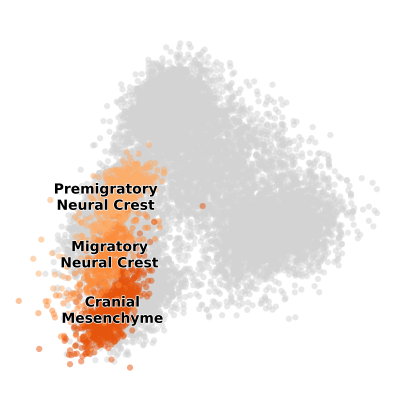

In [15]:
pad = .05
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.embedding(adata_bif, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .5, frameon = False,
                show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
xlim = (xlim[0], xlim[1] - .375)
xpad = pad * (xlim[1] - xlim[0])
ypad = pad * (ylim[1] - ylim[0])

sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = .5,
                palette = palette, legend_loc = 'on data',
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_xlim(xlim[0] - xpad, xlim[1] + xpad)
ax.set_ylim(ylim[0] - ypad, ylim[1] + ypad)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Premigratory Neural Crest' : 'Premigratory\nNeural Crest',
    'Migratory Neural Crest'    : 'Migratory\nNeural Crest',
    'Neuroglial Progenitors'    : '',
    'Cranial Mesenchyme'        : 'Cranial\nMesenchyme'}

pos_dict = {
    'Premigratory Neural Crest' : (-.125, .025)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'celltypes.pdf')
plt.savefig(fn, bbox_inches = 'tight')

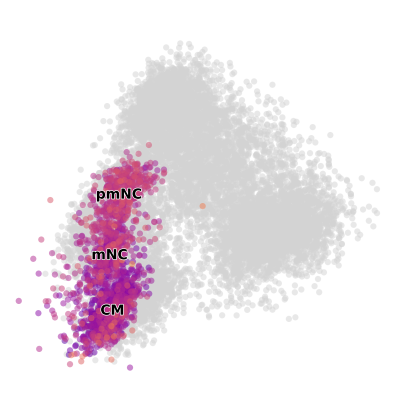

In [16]:
pad = .05
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.embedding(adata_bif, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .5, frameon = False,
                show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
xlim = (xlim[0], xlim[1] - .375)
xpad = pad * (xlim[1] - xlim[0])
ypad = pad * (ylim[1] - ylim[0])

sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'GSE162534', cmap = 'plasma', vmin = -.3,
                vmax = .4, size = 80, alpha = .5, colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = 0,
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_xlim(xlim[0] - xpad, xlim[1] + xpad)
ax.set_ylim(ylim[0] - ypad, ylim[1] + ypad)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Premigratory Neural Crest' : 'pmNC',
    'Migratory Neural Crest'    : 'mNC',
    'Neuroglial Progenitors'    : '',
    'Cranial Mesenchyme'        : 'CM'}

for label in ax.texts:
    _label_ = label.get_text()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])

fn = os.path.join(pth_out, 'Gast_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_1341959/2715579696.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax = cax)


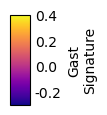

In [17]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Gast\nSignature')
ticks = np.asarray([-.2, 0, .2, .4])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'Gast_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')

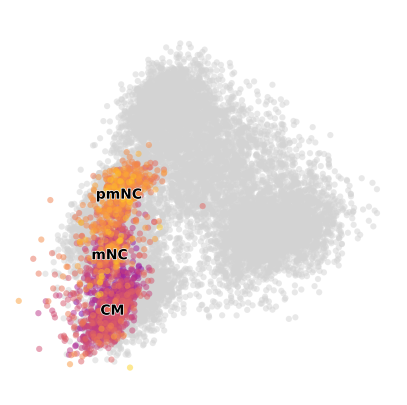

In [18]:
pad = .05
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.embedding(adata_bif, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .5, frameon = False,
                show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
xlim = (xlim[0], xlim[1] - .375)
xpad = pad * (xlim[1] - xlim[0])
ypad = pad * (ylim[1] - ylim[0])

sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'GSE229103', cmap = 'plasma', vmin = -.3,
                vmax = .4, size = 80, alpha = .5, colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = 0,
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_xlim(xlim[0] - xpad, xlim[1] + xpad)
ax.set_ylim(ylim[0] - ypad, ylim[1] + ypad)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Premigratory Neural Crest' : 'pmNC',
    'Migratory Neural Crest'    : 'mNC',
    'Neuroglial Progenitors'    : '',
    'Cranial Mesenchyme'        : 'CM'}

for label in ax.texts:
    _label_ = label.get_text()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])

fn = os.path.join(pth_out, 'pSom_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_1341959/805905156.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax = cax)


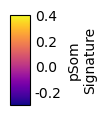

In [19]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('pSom\nSignature')
ticks = np.asarray([-.2, 0, .2, .4])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'pSom_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')